 # Monte Carlo Prediction

Gridworld environment created with a random policy.


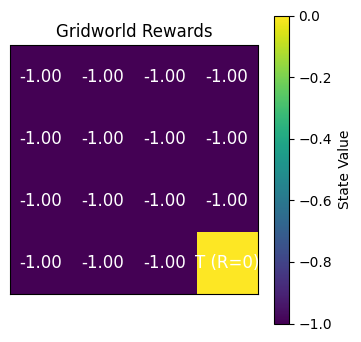

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
class Gridworld:
    def __init__(self, shape=(4, 4)):
        self.shape = shape
        self.n_states = np.prod(self.shape)
        self.n_actions = 4
        self.V = np.zeros(self.n_states)
        self.terminal_states = [self.coords_to_state((3, 3))]
        self.rewards = np.full(self.n_states, -1)
        self.rewards[self.terminal_states] = 0
        self.policy = np.full((self.n_states, self.n_actions), 1/self.n_actions)
    def state_to_coords(self, s):
        return (s // self.shape[1], s % self.shape[1])
    def coords_to_state(self, coords):
        return coords[0] * self.shape[1] + coords[1]
    def step(self, state, action):
        row, col = self.state_to_coords(state)
        if state in self.terminal_states:
            return state, 0, True
        next_row, next_col = row, col
        if action == 0:
            next_row = max(0, row - 1)
        elif action == 1:
            next_row = min(self.shape[0] - 1, row + 1)
        elif action == 2:
            next_col = max(0, col - 1)
        elif action == 3:
            next_col = min(self.shape[1] - 1, col + 1)
        next_state = self.coords_to_state((next_row, next_col))
        reward = self.rewards[next_state]
        done = next_state in self.terminal_states
        return next_state, reward, done
    def display_grid(self, values=None, title="Gridworld State Values"):
        grid = np.zeros(self.shape)
        if values is None:
            values = self.V
        for s in range(self.n_states):
            row, col = self.state_to_coords(s)
            grid[row, col] = values[s]
        plt.figure(figsize=(4, 4))
        plt.imshow(grid, cmap='viridis', origin='upper')
        for r in range(self.shape[0]):
            for c in range(self.shape[1]):
                state = self.coords_to_state((r, c))
                if state in self.terminal_states:
                    plt.text(c, r, f'T (R={self.rewards[state]})', ha='center', va='center', color='white', fontsize=12)
                else:
                    plt.text(c, r, f'{grid[r, c]:.2f}', ha='center', va='center', color='white', fontsize=12)
        plt.colorbar(label='State Value')
        plt.title(title)
        plt.xticks([])
        plt.yticks([])
        plt.grid(True)
        plt.show()
env = Gridworld()
print("Gridworld environment created with a random policy.")
env.display_grid(env.rewards, title="Gridworld Rewards")

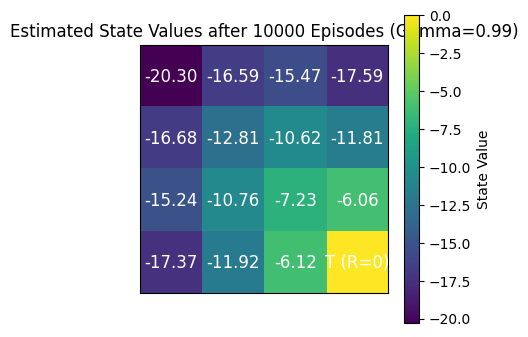

Monte Carlo Prediction complete. Estimated state values:
[[-20.3009056  -16.58930585 -15.46743206 -17.59120278]
 [-16.67559255 -12.81028097 -10.61625899 -11.80889655]
 [-15.23954172 -10.75696741  -7.23206704  -6.05561444]
 [-17.36934677 -11.9190139   -6.1223221    0.        ]]


In [ ]:
def generate_episode(env, policy):
    episode = []
    state = np.random.randint(0, env.n_states)
    done = False
    while not done:
        action_probabilities = policy[state]
        action = np.random.choice(env.n_actions, p=action_probabilities)
        next_state, reward, done = env.step(state, action)
        episode.append((state, action, reward))
        state = next_state
    return episode
def monte_carlo_prediction(env, policy, num_episodes, gamma=0.99):
    returns_sum = np.zeros(env.n_states)
    returns_count = np.zeros(env.n_states)
    V = np.zeros(env.n_states)
    for i in range(num_episodes):
        episode = generate_episode(env, policy)
        G = 0
        states_in_episode = set()
        for t in reversed(range(len(episode))):
            state, action, reward = episode[t]
            G = gamma * G + reward
            if state not in states_in_episode:
                returns_sum[state] += G
                returns_count[state] += 1
                states_in_episode.add(state)
    for s in range(env.n_states):
        if returns_count[s] > 0:
            V[s] = returns_sum[s] / returns_count[s]
    return V
num_episodes = 10000
gamma = 0.99
estimated_V = monte_carlo_prediction(env, env.policy, num_episodes, gamma)
env.display_grid(estimated_V, title=f"Estimated State Values after {num_episodes} Episodes (Gamma={gamma})")
print("Monte Carlo Prediction complete. Estimated state values:")
print(estimated_V.reshape(env.shape))